# Group Assignment 2 — Problem 1
## Smart Home Energy Consumption Analysis using Bayesian Networks

**Group members:**

1. Siddharth — B24EC017
2. Parveen — B24EC013
3. Rakesh — B24EC023
4. Jnaneswar — B24ME027

Requirements: `pip install pgmpy numpy pandas networkx matplotlib`. Run all cells top to bottom; screenshots, tables and plots are saved to `outputs/`. Random seed: 42.

### Setup

In [1]:
%matplotlib inline

import os
import sys
import itertools
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

SEED = 42                       # fixed random seed (reported, for reproducibility)
SIZES = [500, 5000, 20000]      # dataset sizes for Part C


# ---------------------------------------------------------------------------
# Small helper: print to console AND save to a log file
# ---------------------------------------------------------------------------


def header(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def save_table_image(df, filename, title, col_width=1.6, fontsize=10):
    """Render a DataFrame as a PNG 'screenshot' of the output table."""
    nrows, ncols = df.shape
    fig_w = max(6, col_width * (ncols + 1))
    fig_h = 0.32 * (nrows + 1) + 0.5
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")
    tbl = ax.table(cellText=df.values,
                   colLabels=list(df.columns),
                   rowLabels=list(df.index) if df.index.name != "__noindex__" else None,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(fontsize)
    tbl.auto_set_column_width(list(range(-1, ncols)))
    tbl.scale(1, 1.5)
    for (r, c), cell in tbl.get_celld().items():
        if r == 0 or c == -1:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#e8eef7")
    ax.set_title(title, fontsize=12, weight="bold", pad=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, filename), dpi=150, bbox_inches="tight")
    plt.close(fig)

### Variables, states and network structure

In [2]:
# ===========================================================================
# STATE NAMES (order matters: first state = column 0 in every CPT)
# ===========================================================================
STATES = {
    "Weather":           ["Hot", "Mild", "Cold"],
    "DayType":           ["Weekday", "Weekend"],
    "Occupancy":         ["High", "Low"],
    "AC":                ["On", "Off"],
    "ApplianceLoad":     ["Heavy", "Light"],
    "EnergyConsumption": ["High", "Low"],
}

EDGES = [
    ("DayType", "Occupancy"),
    ("Weather", "AC"),
    ("Occupancy", "AC"),
    ("Occupancy", "ApplianceLoad"),
    ("AC", "EnergyConsumption"),
    ("ApplianceLoad", "EnergyConsumption"),
]

## Part A: Expert Bayesian Network

### A.1 Construct the network
### A.2 Define CPTs and verify they sum to 1

In [3]:
# ===========================================================================
# PART A: EXPERT BAYESIAN NETWORK
# ===========================================================================
header("PART A: EXPERT BAYESIAN NETWORK")

# ---------------- A.1  Construct the network ------------------------------
print("\nA.1  Constructing the Bayesian Network")
expert = DiscreteBayesianNetwork(EDGES)
print("Nodes:", list(expert.nodes()))
print("Edges:", list(expert.edges()))

# ---------------- A.2  Define CPTs -----------------------------------------
print("\nA.2  Defining CPTs (complement = 1 - given value)")

cpd_W = TabularCPD("Weather", 3, [[0.50], [0.30], [0.20]],
                   state_names={"Weather": STATES["Weather"]})

cpd_D = TabularCPD("DayType", 2, [[0.70], [0.30]],
                   state_names={"DayType": STATES["DayType"]})

# Occupancy | DayType   (columns: Weekday, Weekend)
cpd_O = TabularCPD("Occupancy", 2,
                   [[0.45, 0.80],
                    [0.55, 0.20]],
                   evidence=["DayType"], evidence_card=[2],
                   state_names={"Occupancy": STATES["Occupancy"],
                                "DayType": STATES["DayType"]})

# AC | Weather, Occupancy
# columns: (Hot,High) (Hot,Low) (Mild,High) (Mild,Low) (Cold,High) (Cold,Low)
ac_on = [0.90, 0.60, 0.40, 0.15, 0.10, 0.05]
cpd_A = TabularCPD("AC", 2,
                   [ac_on,
                    [1 - p for p in ac_on]],
                   evidence=["Weather", "Occupancy"], evidence_card=[3, 2],
                   state_names={"AC": STATES["AC"],
                                "Weather": STATES["Weather"],
                                "Occupancy": STATES["Occupancy"]})

# ApplianceLoad | Occupancy   (columns: High, Low)
cpd_L = TabularCPD("ApplianceLoad", 2,
                   [[0.75, 0.35],
                    [0.25, 0.65]],
                   evidence=["Occupancy"], evidence_card=[2],
                   state_names={"ApplianceLoad": STATES["ApplianceLoad"],
                                "Occupancy": STATES["Occupancy"]})

# EnergyConsumption | AC, ApplianceLoad
# columns: (On,Heavy) (On,Light) (Off,Heavy) (Off,Light)
e_high = [0.92, 0.68, 0.55, 0.12]
cpd_E = TabularCPD("EnergyConsumption", 2,
                   [e_high,
                    [1 - p for p in e_high]],
                   evidence=["AC", "ApplianceLoad"], evidence_card=[2, 2],
                   state_names={"EnergyConsumption": STATES["EnergyConsumption"],
                                "AC": STATES["AC"],
                                "ApplianceLoad": STATES["ApplianceLoad"]})

expert.add_cpds(cpd_W, cpd_D, cpd_O, cpd_A, cpd_L, cpd_E)

for cpd in expert.get_cpds():
    print(f"\nCPT of {cpd.variable}:")
    print(cpd)

# Programmatic check: every column (= every parent configuration) sums to 1
print("\nA.2  Verifying that every CPT column sums to 1 for every parent configuration")
rows = []
all_ok = True
for cpd in expert.get_cpds():
    var = cpd.variable
    parents = cpd.variables[1:]
    vals = cpd.get_values()                  # shape: (card(var), #parent configs)
    if parents:
        configs = list(itertools.product(*[STATES[p] for p in parents]))
    else:
        configs = [()]
    for j, cfg in enumerate(configs):
        s = vals[:, j].sum()
        ok = np.isclose(s, 1.0)
        all_ok &= ok
        cfg_str = ", ".join(f"{p}={v}" for p, v in zip(parents, cfg)) or "(no parents)"
        rows.append([var, cfg_str, f"{s:.4f}", "PASS" if ok else "FAIL"])
check_df = pd.DataFrame(rows, columns=["Variable", "Parent configuration", "Sum", "Check"])
print(check_df.to_string(index=False))
print("All CPT columns sum to 1:", all_ok)
print("pgmpy check_model():", expert.check_model())
check_df.index.name = "__noindex__"
save_table_image(check_df, "A2_cpt_sum_check.png", "Part A.2 - CPT sum check (each parent configuration)",
                 col_width=2.2)


PART A: EXPERT BAYESIAN NETWORK

A.1  Constructing the Bayesian Network
Nodes: ['DayType', 'Occupancy', 'Weather', 'AC', 'ApplianceLoad', 'EnergyConsumption']
Edges: [('DayType', 'Occupancy'), ('Occupancy', 'AC'), ('Occupancy', 'ApplianceLoad'), ('Weather', 'AC'), ('AC', 'EnergyConsumption'), ('ApplianceLoad', 'EnergyConsumption')]

A.2  Defining CPTs (complement = 1 - given value)

CPT of Weather:
+---------------+-----+
| Weather(Hot)  | 0.5 |
+---------------+-----+
| Weather(Mild) | 0.3 |
+---------------+-----+
| Weather(Cold) | 0.2 |
+---------------+-----+

CPT of DayType:
+------------------+-----+
| DayType(Weekday) | 0.7 |
+------------------+-----+
| DayType(Weekend) | 0.3 |
+------------------+-----+

CPT of Occupancy:
+-----------------+------------------+------------------+
| DayType         | DayType(Weekday) | DayType(Weekend) |
+-----------------+------------------+------------------+
| Occupancy(High) | 0.45             | 0.8              |
+-----------------+-------

### A.3 Visualise the network


A.3  Visualising the network -> outputs/A3_bayesian_network.png


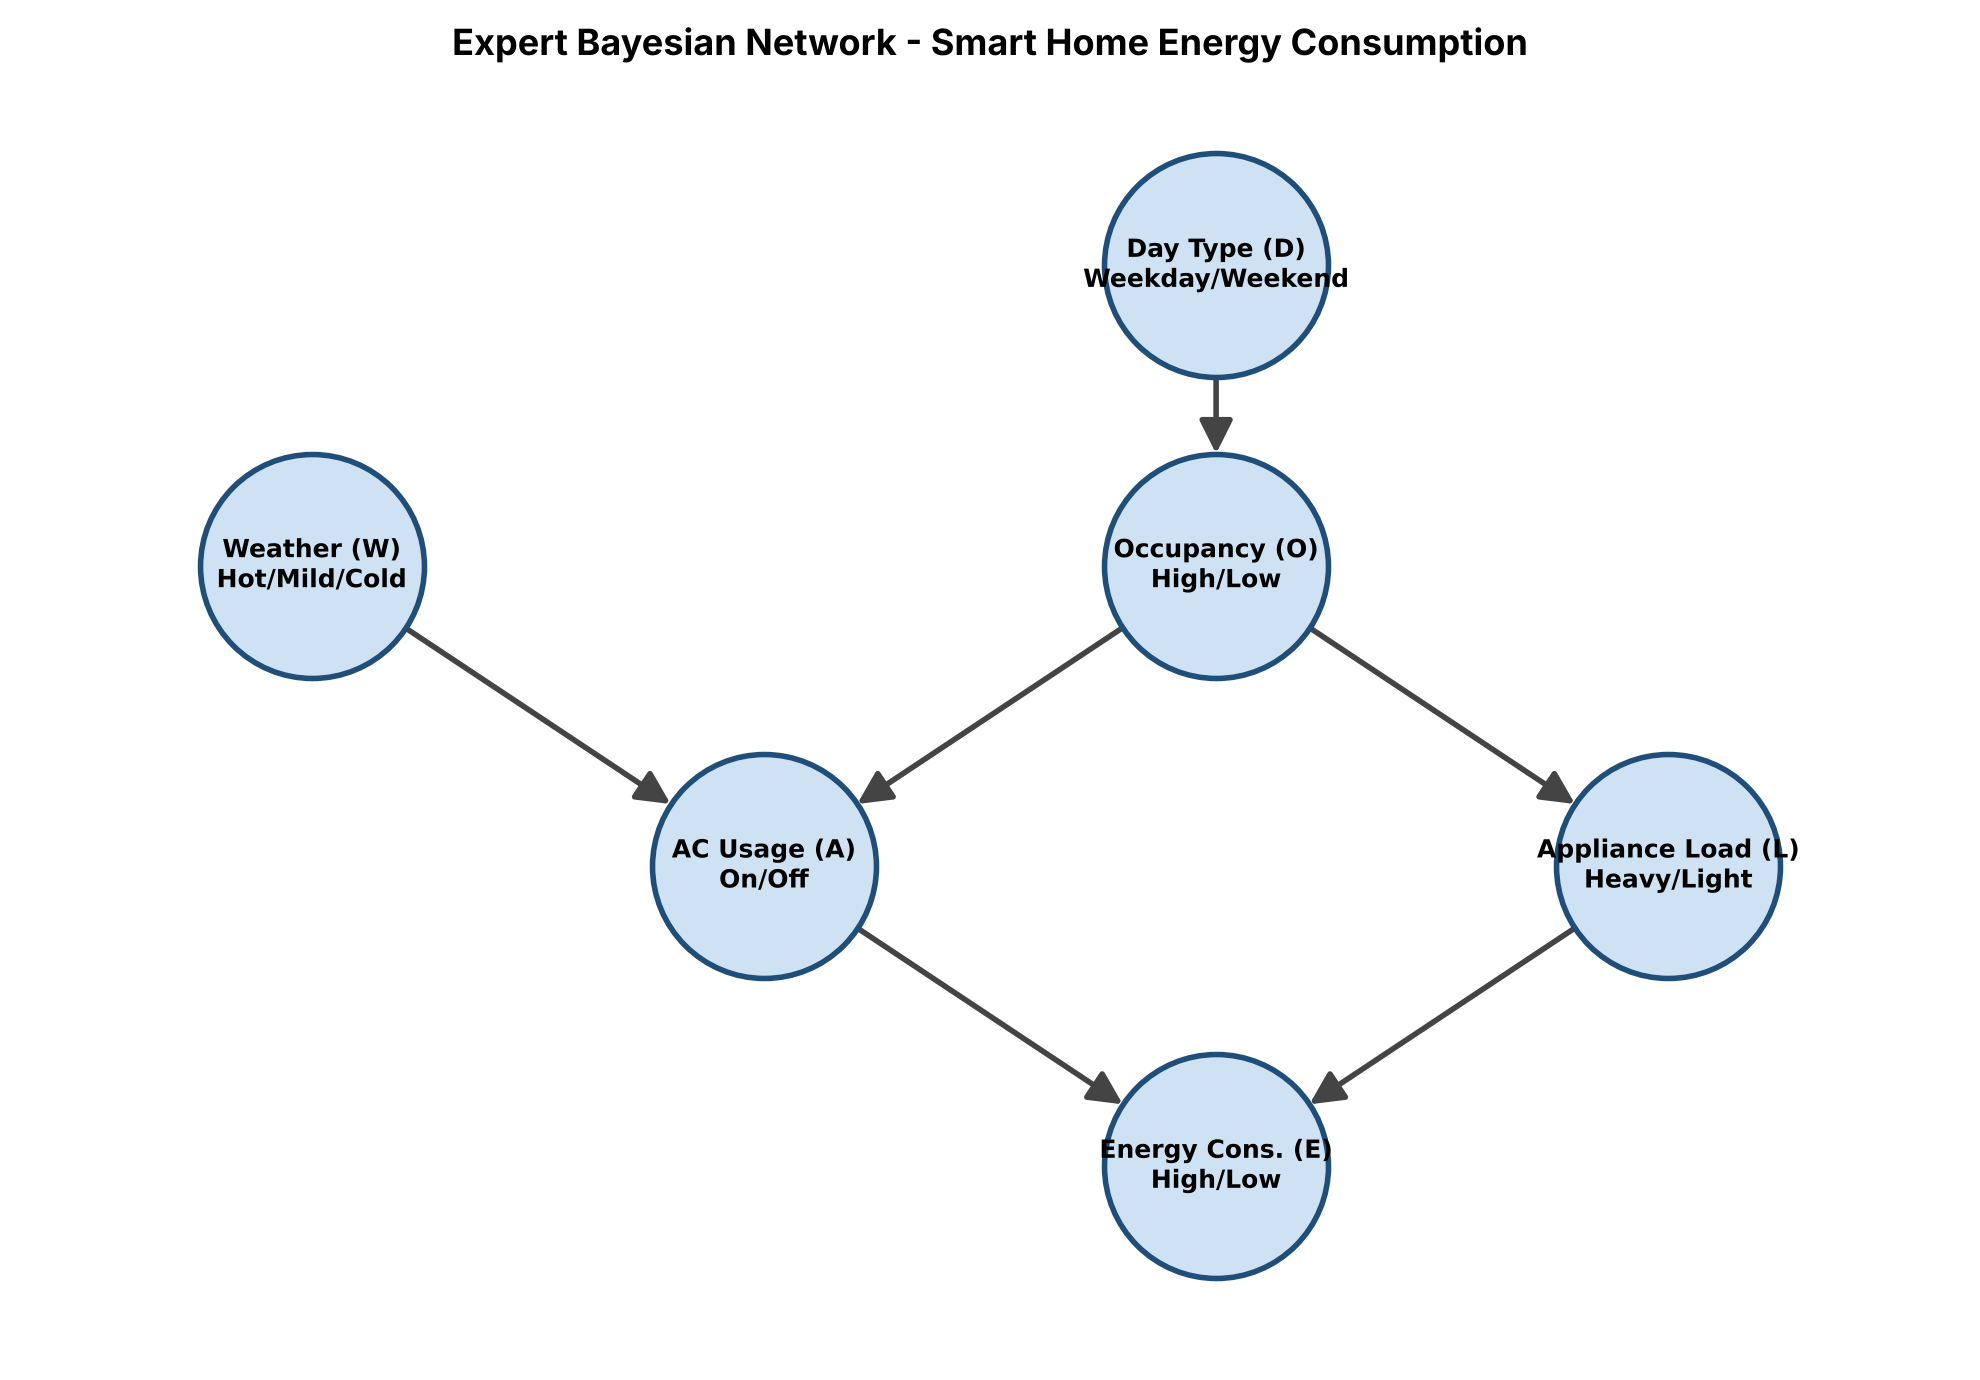

In [4]:
# ---------------- A.3  Visualise ------------------------------------------
print("\nA.3  Visualising the network -> outputs/A3_bayesian_network.png")
pos = {
    "Weather": (0, 2), "DayType": (2.4, 3),
    "Occupancy": (2.4, 2), "AC": (1.2, 1),
    "ApplianceLoad": (3.6, 1), "EnergyConsumption": (2.4, 0),
}
labels = {
    "Weather": "Weather (W)\nHot/Mild/Cold", "DayType": "Day Type (D)\nWeekday/Weekend",
    "Occupancy": "Occupancy (O)\nHigh/Low", "AC": "AC Usage (A)\nOn/Off",
    "ApplianceLoad": "Appliance Load (L)\nHeavy/Light",
    "EnergyConsumption": "Energy Cons. (E)\nHigh/Low",
}
G = nx.DiGraph(EDGES)
fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx_nodes(G, pos, node_size=6500, node_color="#cfe2f3",
                       edgecolors="#1f4e79", linewidths=2, ax=ax)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=25, width=2,
                       node_size=6500, edge_color="#444", ax=ax)
nx.draw_networkx_labels(G, pos, labels, font_size=9, font_weight="bold", ax=ax)
ax.set_title("Expert Bayesian Network - Smart Home Energy Consumption",
             fontsize=13, weight="bold")
ax.axis("off")
ax.margins(0.15)
plt.tight_layout()
plt.savefig(os.path.join(OUT, "A3_bayesian_network.png"), dpi=150)
plt.show()

### A.4 Inference queries Q1–Q7

In [5]:
# ---------------- A.4  Queries Q1 - Q7 ------------------------------------
QUERIES = {
    "Q1": ("EnergyConsumption", "High", {}),
    "Q2": ("EnergyConsumption", "High", {"Weather": "Hot"}),
    "Q3": ("EnergyConsumption", "High", {"DayType": "Weekend"}),
    "Q4": ("EnergyConsumption", "High", {"Weather": "Cold", "Occupancy": "High"}),
    "Q5": ("Weather", "Hot", {"EnergyConsumption": "High"}),
    "Q6": ("AC", "On", {"EnergyConsumption": "High"}),
    "Q7": ("AC", "On", {"EnergyConsumption": "High", "ApplianceLoad": "Heavy"}),
}


def q_text(qid):
    var, val, ev = QUERIES[qid]
    s = f"P({var}={val}"
    if ev:
        s += " | " + ", ".join(f"{k}={v}" for k, v in ev.items())
    return s + ")"


def prob(model, var, val, evidence):
    infer = VariableElimination(model)
    res = infer.query([var], evidence=evidence if evidence else None, show_progress=False)
    return float(res.get_value(**{var: val}))


def run_queries(model):
    return {q: prob(model, *QUERIES[q]) for q in QUERIES}


print("\nA.4  Inference results (Variable Elimination) on the expert model")
expert_res = run_queries(expert)
qrows = []
for q, p in expert_res.items():
    print(f"  {q}: {q_text(q):<60s} = {p:.4f}")
    qrows.append([q, q_text(q), f"{p:.4f}"])
qdf = pd.DataFrame(qrows, columns=["Query", "Expression", "Probability"])
qdf.index.name = "__noindex__"
save_table_image(qdf, "A4_expert_queries.png", "Part A.4 - Expert model queries Q1-Q7", col_width=3.0)


A.4  Inference results (Variable Elimination) on the expert model
  Q1: P(EnergyConsumption=High)                                    = 0.5806
  Q2: P(EnergyConsumption=High | Weather=Hot)                      = 0.7063
  Q3: P(EnergyConsumption=High | DayType=Weekend)                  = 0.6402
  Q4: P(EnergyConsumption=High | Weather=Cold, Occupancy=High)     = 0.4843
  Q5: P(Weather=Hot | EnergyConsumption=High)                      = 0.6082
  Q6: P(AC=On | EnergyConsumption=High)                            = 0.6929
  Q7: P(AC=On | EnergyConsumption=High, ApplianceLoad=Heavy)       = 0.6499


### A.5 Q6 vs Q7 (explaining away)

In [6]:
# ---------------- A.5  Explaining away ------------------------------------
print("\nA.5  Explaining away: Q6 vs Q7")
print(f"  Q6 = P(AC=On | E=High)                    = {expert_res['Q6']:.4f}")
print(f"  Q7 = P(AC=On | E=High, Load=Heavy)        = {expert_res['Q7']:.4f}")
print(f"  Change (Q7 - Q6)                          = {expert_res['Q7'] - expert_res['Q6']:+.4f}")
# extra supporting numbers
p_ac_prior = prob(expert, "AC", "On", {})
p_ac_heavy = prob(expert, "AC", "On", {"ApplianceLoad": "Heavy"})
p_ac_light_e = prob(expert, "AC", "On", {"EnergyConsumption": "High", "ApplianceLoad": "Light"})
print(f"  Supporting: P(AC=On)                       = {p_ac_prior:.4f}")
print(f"  Supporting: P(AC=On | Load=Heavy)          = {p_ac_heavy:.4f}")
print(f"  Supporting: P(AC=On | E=High, Load=Light)  = {p_ac_light_e:.4f}")


A.5  Explaining away: Q6 vs Q7
  Q6 = P(AC=On | E=High)                    = 0.6929
  Q7 = P(AC=On | E=High, Load=Heavy)        = 0.6499
  Change (Q7 - Q6)                          = -0.0430
  Supporting: P(AC=On)                       = 0.4854
  Supporting: P(AC=On | Load=Heavy)          = 0.5260
  Supporting: P(AC=On | E=High, Load=Light)  = 0.8112


### A.6 Q1 by hand, checked against code

In [7]:
# ---------------- A.6  Hand calculation of Q1 ------------------------------
print("\nA.6  Hand calculation of Q1 = P(E=High)  (step-by-step summation)")
pW = {"Hot": .5, "Mild": .3, "Cold": .2}
pD = {"Weekday": .7, "Weekend": .3}
pO_D = {"Weekday": .45, "Weekend": .80}
pA_WO = {("Hot", "High"): .9, ("Hot", "Low"): .6, ("Mild", "High"): .4,
         ("Mild", "Low"): .15, ("Cold", "High"): .1, ("Cold", "Low"): .05}
pL_O = {"High": .75, "Low": .35}
pE_AL = {("On", "Heavy"): .92, ("On", "Light"): .68, ("Off", "Heavy"): .55, ("Off", "Light"): .12}

pOH = sum(pD[d] * pO_D[d] for d in pD)
print(f"  Step 1: P(O=High) = 0.70*0.45 + 0.30*0.80 = {pOH:.4f};  P(O=Low) = {1-pOH:.4f}")
pO = {"High": pOH, "Low": 1 - pOH}
pAon_O = {o: sum(pW[w] * pA_WO[(w, o)] for w in pW) for o in ["High", "Low"]}
print(f"  Step 2: P(A=On|O=High) = 0.5*0.90 + 0.3*0.40 + 0.2*0.10 = {pAon_O['High']:.4f}")
print(f"          P(A=On|O=Low)  = 0.5*0.60 + 0.3*0.15 + 0.2*0.05 = {pAon_O['Low']:.4f}")
total = 0.0
for o in ["High", "Low"]:
    pA = {"On": pAon_O[o], "Off": 1 - pAon_O[o]}
    pL = {"Heavy": pL_O[o], "Light": 1 - pL_O[o]}
    inner = sum(pA[a] * pL[l] * pE_AL[(a, l)] for a in pA for l in pL)
    print(f"  Step 3: P(E=High|O={o}) = sum_a sum_l P(a|O) P(l|O) P(E=H|a,l) = {inner:.6f}")
    total += pO[o] * inner
print(f"  Step 4: P(E=High) = 0.555 * P(E=H|O=High) + 0.445 * P(E=H|O=Low) = {total:.6f}")

# brute-force full joint enumeration as a second check
brute = 0.0
for w, d, o, a, l in itertools.product(pW, pD, ["High", "Low"], ["On", "Off"], ["Heavy", "Light"]):
    po = pO_D[d] if o == "High" else 1 - pO_D[d]
    pa = pA_WO[(w, o)] if a == "On" else 1 - pA_WO[(w, o)]
    pl = pL_O[o] if l == "Heavy" else 1 - pL_O[o]
    brute += pW[w] * pD[d] * po * pa * pl * pE_AL[(a, l)]
print(f"  Full-joint brute force (48 terms)        = {brute:.6f}")
print(f"  pgmpy Variable Elimination              = {expert_res['Q1']:.6f}")
print("  Match:", np.isclose(total, expert_res["Q1"]) and np.isclose(brute, expert_res["Q1"]))


A.6  Hand calculation of Q1 = P(E=High)  (step-by-step summation)
  Step 1: P(O=High) = 0.70*0.45 + 0.30*0.80 = 0.5550;  P(O=Low) = 0.4450
  Step 2: P(A=On|O=High) = 0.5*0.90 + 0.3*0.40 + 0.2*0.10 = 0.5900
          P(A=On|O=Low)  = 0.5*0.60 + 0.3*0.15 + 0.2*0.05 = 0.3550
  Step 3: P(E=High|O=High) = sum_a sum_l P(a|O) P(l|O) P(E=H|a,l) = 0.688825
  Step 3: P(E=High|O=Low) = sum_a sum_l P(a|O) P(l|O) P(E=H|a,l) = 0.445692
  Step 4: P(E=High) = 0.555 * P(E=H|O=High) + 0.445 * P(E=H|O=Low) = 0.580631
  Full-joint brute force (48 terms)        = 0.580631
  pgmpy Variable Elimination              = 0.580631
  Match: True


## Part B: Conditional independence (d-separation)

In [8]:
# ===========================================================================
# PART B: CONDITIONAL INDEPENDENCE (d-separation)
# ===========================================================================
header("PART B: CONDITIONAL INDEPENDENCE ANALYSIS (d-separation)")


def dist(model, var, evidence):
    infer = VariableElimination(model)
    r = infer.query([var], evidence=evidence if evidence else None, show_progress=False)
    return np.array([r.get_value(**{var: s}) for s in STATES[var]])


tests = [
    ("B.1", "Weather ⊥ DayType", "Weather", "DayType", [],
     {}, {"DayType": "Weekend"}),
    ("B.2", "Weather ⊥ DayType | EnergyConsumption", "Weather", "DayType", ["EnergyConsumption"],
     {"EnergyConsumption": "High"}, {"EnergyConsumption": "High", "DayType": "Weekend"}),
    ("B.3", "Weather ⊥ ApplianceLoad | Occupancy", "Weather", "ApplianceLoad", ["Occupancy"],
     {"Occupancy": "High"}, {"Occupancy": "High", "ApplianceLoad": "Heavy"}),
]

brows = []
for tid, stmt, x, y, z, ev1, ev2 in tests:
    dconn = expert.is_dconnected(x, y, observed=z)
    d1, d2 = dist(expert, "Weather", ev1), dist(expert, "Weather", ev2)
    # exhaustive numerical check: every value of Y and Z
    max_gap = 0.0
    z_cfgs = list(itertools.product(*[STATES[v] for v in z])) if z else [()]
    for zc in z_cfgs:
        base_ev = dict(zip(z, zc))
        base = dist(expert, x, base_ev)
        for yv in STATES[y]:
            ev = dict(base_ev); ev[y] = yv
            max_gap = max(max_gap, np.abs(dist(expert, x, ev) - base).max())
    holds = not dconn
    print(f"\n{tid}  {stmt}")
    print(f"   pgmpy is_dconnected -> {dconn}  =>  independence {'HOLDS' if holds else 'DOES NOT HOLD'}")
    e1 = ", ".join(f"{k}={v}" for k, v in ev1.items()) or "-"
    e2 = ", ".join(f"{k}={v}" for k, v in ev2.items())
    short = lambda e: (e.replace("EnergyConsumption", "E").replace("DayType", "D")
                        .replace("Occupancy", "O").replace("ApplianceLoad", "L"))
    print(f"   P(Weather | {e1:<35s}) = Hot {d1[0]:.4f}, Mild {d1[1]:.4f}, Cold {d1[2]:.4f}")
    print(f"   P(Weather | {e2:<35s}) = Hot {d2[0]:.4f}, Mild {d2[1]:.4f}, Cold {d2[2]:.4f}")
    print(f"   Max |difference| over all values of {y}{' and ' + ', '.join(z) if z else ''}: {max_gap:.6f}")
    brows.append([tid, stmt,
                  f"P(W=Hot|{short(e1)}) = {d1[0]:.4f}" if ev1 else f"P(W=Hot) = {d1[0]:.4f}",
                  f"P(W=Hot|{short(e2)}) = {d2[0]:.4f}",
                  f"{max_gap:.4f}",
                  "Holds" if holds else "Does NOT hold"])
bdf = pd.DataFrame(brows, columns=["Part", "Statement", "Without extra evidence",
                                   "With extra evidence", "Max |diff|", "Result"])
bdf.index.name = "__noindex__"
save_table_image(bdf, "B_independence_checks.png", "Part B - d-separation numerical verification",
                 col_width=2.6, fontsize=8)


PART B: CONDITIONAL INDEPENDENCE ANALYSIS (d-separation)

B.1  Weather ⊥ DayType
   pgmpy is_dconnected -> False  =>  independence HOLDS
   P(Weather | -                                  ) = Hot 0.5000, Mild 0.3000, Cold 0.2000
   P(Weather | DayType=Weekend                    ) = Hot 0.5000, Mild 0.3000, Cold 0.2000
   Max |difference| over all values of DayType: 0.000000

B.2  Weather ⊥ DayType | EnergyConsumption
   pgmpy is_dconnected -> True  =>  independence DOES NOT HOLD
   P(Weather | EnergyConsumption=High             ) = Hot 0.6082, Mild 0.2540, Cold 0.1378
   P(Weather | EnergyConsumption=High, DayType=Weekend) = Hot 0.5998, Mild 0.2608, Cold 0.1395
   Max |difference| over all values of DayType and EnergyConsumption: 0.027699

B.3  Weather ⊥ ApplianceLoad | Occupancy
   pgmpy is_dconnected -> False  =>  independence HOLDS
   P(Weather | Occupancy=High                     ) = Hot 0.5000, Mild 0.3000, Cold 0.2000
   P(Weather | Occupancy=High, ApplianceLoad=Heavy) = Hot 0.50

## Part C: Synthetic data (ancestral sampling)

In [9]:
# ===========================================================================
# PART C: SYNTHETIC DATA GENERATION (own ancestral sampler)
# ===========================================================================
header("PART C: SYNTHETIC DATA GENERATION (ancestral sampling)")

TOPO_ORDER = list(nx.topological_sort(nx.DiGraph(EDGES)))
print("Topological order used:", TOPO_ORDER)
print("Random seed:", SEED)


def ancestral_sample(model, n, seed):
    """Sample n rows by visiting nodes in topological order and drawing each
    node from its CPT row selected by the already-sampled parent values."""
    rng = np.random.default_rng(seed)
    cpds = {c.variable: c for c in model.get_cpds()}
    data = {v: np.empty(n, dtype=object) for v in TOPO_ORDER}
    for i in range(n):
        sample = {}
        for v in TOPO_ORDER:
            cpd = cpds[v]
            parents = cpd.variables[1:]
            vals = cpd.get_values()
            if parents:
                # column index for this parent configuration (row-major order)
                idx = 0
                for p in parents:
                    idx = idx * len(STATES[p]) + STATES[p].index(sample[p])
                probs = vals[:, idx]
            else:
                probs = vals[:, 0]
            sample[v] = STATES[v][rng.choice(len(probs), p=probs)]
            data[v][i] = sample[v]
    return pd.DataFrame(data)[list(STATES)]


datasets = {}
for k, n in enumerate(SIZES):
    df = ancestral_sample(expert, n, SEED + k)      # seeds 42, 43, 44
    datasets[n] = df
    df.to_csv(os.path.join(OUT, f"C_dataset_{n}.csv"), index=False)

    print(f"\n--- Dataset with {n} samples (seed = {SEED + k}) ---")
    print(df.head().to_string())
    wf = df["Weather"].value_counts(normalize=True).reindex(STATES["Weather"])
    wc = df["Weather"].value_counts().reindex(STATES["Weather"])
    print("\nEmpirical frequency of Weather (true: Hot 0.50, Mild 0.30, Cold 0.20):")
    for s in STATES["Weather"]:
        print(f"   {s:<5s}: count = {wc[s]:>6d}   frequency = {wf[s]:.4f}")
    ct = pd.crosstab(df["Weather"], df["Occupancy"]).reindex(
        index=STATES["Weather"], columns=STATES["Occupancy"]).fillna(0).astype(int)
    print("\nNumber of samples for each (Weather, Occupancy) combination:")
    print(ct.to_string())

    # screenshot image
    tab = pd.DataFrame({
        "Count": wc.values,
        "Empirical freq": [f"{x:.4f}" for x in wf.values],
        "True prob": ["0.50", "0.30", "0.20"],
        "Occ=High": ct["High"].values,
        "Occ=Low": ct["Low"].values,
    }, index=STATES["Weather"])
    save_table_image(tab, f"C_dataset_{n}_summary.png",
                     f"Part C - Dataset n={n} (seed {SEED + k}): Weather frequency & (Weather, Occupancy) counts")


PART C: SYNTHETIC DATA GENERATION (ancestral sampling)
Topological order used: ['DayType', 'Weather', 'Occupancy', 'AC', 'ApplianceLoad', 'EnergyConsumption']
Random seed: 42

--- Dataset with 500 samples (seed = 42) ---
  Weather  DayType Occupancy   AC ApplianceLoad EnergyConsumption
0     Hot  Weekend       Low  Off         Heavy               Low
1    Mild  Weekend      High  Off         Heavy               Low
2    Cold  Weekday      High  Off         Heavy              High
3    Mild  Weekend      High   On         Light               Low
4     Hot  Weekend      High   On         Heavy              High

Empirical frequency of Weather (true: Hot 0.50, Mild 0.30, Cold 0.20):
   Hot  : count =    246   frequency = 0.4920
   Mild : count =    150   frequency = 0.3000
   Cold : count =    104   frequency = 0.2080

Number of samples for each (Weather, Occupancy) combination:
Occupancy  High  Low
Weather             
Hot         145  101
Mild         78   72
Cold         65   39



--- Dataset with 5000 samples (seed = 43) ---
  Weather  DayType Occupancy   AC ApplianceLoad EnergyConsumption
0     Hot  Weekday      High   On         Heavy              High
1     Hot  Weekend      High   On         Light               Low
2     Hot  Weekday      High   On         Heavy               Low
3    Mild  Weekend      High  Off         Heavy               Low
4     Hot  Weekend      High   On         Heavy              High

Empirical frequency of Weather (true: Hot 0.50, Mild 0.30, Cold 0.20):
   Hot  : count =   2495   frequency = 0.4990
   Mild : count =   1533   frequency = 0.3066
   Cold : count =    972   frequency = 0.1944

Number of samples for each (Weather, Occupancy) combination:
Occupancy  High   Low
Weather              
Hot        1404  1091
Mild        856   677
Cold        513   459



--- Dataset with 20000 samples (seed = 44) ---
  Weather  DayType Occupancy   AC ApplianceLoad EnergyConsumption
0     Hot  Weekday      High  Off         Heavy               Low
1     Hot  Weekday       Low  Off         Light               Low
2    Cold  Weekend      High   On         Light               Low
3     Hot  Weekday      High   On         Heavy              High
4     Hot  Weekday       Low   On         Light               Low

Empirical frequency of Weather (true: Hot 0.50, Mild 0.30, Cold 0.20):
   Hot  : count =   9921   frequency = 0.4960
   Mild : count =   6034   frequency = 0.3017
   Cold : count =   4045   frequency = 0.2023

Number of samples for each (Weather, Occupancy) combination:
Occupancy  High   Low
Weather              
Hot        5485  4436
Mild       3363  2671
Cold       2300  1745


## Part D: Learning from data (MLE and BDeu, ESS = 10)

In [10]:
# ===========================================================================
# PART D: LEARNING FROM DATA (MLE and Bayesian BDeu, ESS = 10)
# ===========================================================================
header("PART D: LEARNING FROM DATA (MLE vs Bayesian BDeu, ESS=10)")

learned = {}
results = {"Expert": expert_res}

for n, df in datasets.items():
    print(f"\n################  Dataset size n = {n}  ################")

    # D.1 + D.2 : same structure, two estimators
    mle = DiscreteBayesianNetwork(EDGES)
    mle.add_cpds(*MaximumLikelihoodEstimator(mle, df, state_names=STATES).get_parameters())
    bay = DiscreteBayesianNetwork(EDGES)
    bay.add_cpds(*BayesianEstimator(bay, df, state_names=STATES).get_parameters(
        prior_type="BDeu", equivalent_sample_size=10))
    assert mle.check_model() and bay.check_model()
    learned[n] = {"MLE": mle, "Bayesian": bay}
    print("D.1/D.2  Learned two networks with the expert structure:", list(mle.edges()))

    # D.3 : AC CPT comparison
    cols = list(itertools.product(STATES["Weather"], STATES["Occupancy"]))
    # look values up by NAME (learned CPDs may order parents/states differently)
    def ac_on(model):
        cpd = model.get_cpds("AC")
        return [cpd.get_value(AC="On", Weather=w, Occupancy=o) for w, o in cols]
    exp_vals, mle_vals, bay_vals = ac_on(expert), ac_on(mle), ac_on(bay)
    counts = df.groupby(["Weather", "Occupancy"]).size()
    ac_df = pd.DataFrame({
        "Weather": [c[0] for c in cols],
        "Occupancy": [c[1] for c in cols],
        "N (W,O)": [int(counts.get(c, 0)) for c in cols],
        "Expert P(AC=On)": [f"{v:.4f}" for v in exp_vals],
        "MLE P(AC=On)": [f"{v:.4f}" for v in mle_vals],
        "Bayes P(AC=On)": [f"{v:.4f}" for v in bay_vals],
    })
    print("\nD.3  CPT for AC Usage - P(AC=On | Weather, Occupancy)")
    print(ac_df.to_string(index=False))
    ac_df.index.name = "__noindex__"
    save_table_image(ac_df, f"D3_AC_CPT_n{n}.png",
                     f"Part D.3 - AC CPT: Expert vs learned (n={n})", col_width=1.9)

    # D.4 : queries
    results[f"MLE_{n}"] = run_queries(mle)
    results[f"Bayesian_{n}"] = run_queries(bay)
    print("\nD.4  Queries Q1-Q7 on learned models")
    for q in QUERIES:
        print(f"  {q}: {q_text(q):<58s} MLE = {results[f'MLE_{n}'][q]:.4f}   "
              f"Bayesian = {results[f'Bayesian_{n}'][q]:.4f}")


PART D: LEARNING FROM DATA (MLE vs Bayesian BDeu, ESS=10)

################  Dataset size n = 500  ################


D.1/D.2  Learned two networks with the expert structure: [('DayType', 'Occupancy'), ('Occupancy', 'AC'), ('Occupancy', 'ApplianceLoad'), ('Weather', 'AC'), ('AC', 'EnergyConsumption'), ('ApplianceLoad', 'EnergyConsumption')]

D.3  CPT for AC Usage - P(AC=On | Weather, Occupancy)
Weather Occupancy  N (W,O) Expert P(AC=On) MLE P(AC=On) Bayes P(AC=On)
    Hot      High      145          0.9000       0.8966         0.8920
    Hot       Low      101          0.6000       0.7129         0.7094
   Mild      High       78          0.4000       0.3462         0.3494
   Mild       Low       72          0.1500       0.1806         0.1878
   Cold      High       65          0.1000       0.0923         0.1025
   Cold       Low       39          0.0500       0.0000         0.0205



D.4  Queries Q1-Q7 on learned models
  Q1: P(EnergyConsumption=High)                                  MLE = 0.5822   Bayesian = 0.5807
  Q2: P(EnergyConsumption=High | Weather=Hot)                    MLE = 0.7466   Bayesian = 0.7397
  Q3: P(EnergyConsumption=High | DayType=Weekend)                MLE = 0.6226   Bayesian = 0.6181
  Q4: P(EnergyConsumption=High | Weather=Cold, Occupancy=High)   MLE = 0.4370   Bayesian = 0.4420
  Q5: P(Weather=Hot | EnergyConsumption=High)                    MLE = 0.6309   Bayesian = 0.6227
  Q6: P(AC=On | EnergyConsumption=High)                          MLE = 0.7240   Bayesian = 0.7199
  Q7: P(AC=On | EnergyConsumption=High, ApplianceLoad=Heavy)     MLE = 0.6672   Bayesian = 0.6647

################  Dataset size n = 5000  ################
D.1/D.2  Learned two networks with the expert structure: [('DayType', 'Occupancy'), ('Occupancy', 'AC'), ('Occupancy', 'ApplianceLoad'), ('Weather', 'AC'), ('AC', 'EnergyConsumption'), ('ApplianceLoad', 'EnergyConsump


D.4  Queries Q1-Q7 on learned models
  Q1: P(EnergyConsumption=High)                                  MLE = 0.5853   Bayesian = 0.5852
  Q2: P(EnergyConsumption=High | Weather=Hot)                    MLE = 0.7097   Bayesian = 0.7091
  Q3: P(EnergyConsumption=High | DayType=Weekend)                MLE = 0.6453   Bayesian = 0.6447
  Q4: P(EnergyConsumption=High | Weather=Cold, Occupancy=High)   MLE = 0.4916   Bayesian = 0.4920
  Q5: P(Weather=Hot | EnergyConsumption=High)                    MLE = 0.6050   Bayesian = 0.6043
  Q6: P(AC=On | EnergyConsumption=High)                          MLE = 0.6902   Bayesian = 0.6899
  Q7: P(AC=On | EnergyConsumption=High, ApplianceLoad=Heavy)     MLE = 0.6466   Bayesian = 0.6464

################  Dataset size n = 20000  ################
D.1/D.2  Learned two networks with the expert structure: [('DayType', 'Occupancy'), ('Occupancy', 'AC'), ('Occupancy', 'ApplianceLoad'), ('Weather', 'AC'), ('AC', 'EnergyConsumption'), ('ApplianceLoad', 'EnergyConsum


D.4  Queries Q1-Q7 on learned models
  Q1: P(EnergyConsumption=High)                                  MLE = 0.5797   Bayesian = 0.5796
  Q2: P(EnergyConsumption=High | Weather=Hot)                    MLE = 0.7056   Bayesian = 0.7054
  Q3: P(EnergyConsumption=High | DayType=Weekend)                MLE = 0.6425   Bayesian = 0.6423
  Q4: P(EnergyConsumption=High | Weather=Cold, Occupancy=High)   MLE = 0.4916   Bayesian = 0.4917
  Q5: P(Weather=Hot | EnergyConsumption=High)                    MLE = 0.6038   Bayesian = 0.6036
  Q6: P(AC=On | EnergyConsumption=High)                          MLE = 0.6921   Bayesian = 0.6920
  Q7: P(AC=On | EnergyConsumption=High, ApplianceLoad=Heavy)     MLE = 0.6475   Bayesian = 0.6475


## Part E: Comparative analysis

In [11]:
# ===========================================================================
# PART E: COMPARATIVE ANALYSIS
# ===========================================================================
header("PART E: COMPARATIVE ANALYSIS")

mean_diff = {"MLE": [], "Bayesian": []}
comp_tables = {}
for n in SIZES:
    rows = []
    for q in QUERIES:
        e, m, b = expert_res[q], results[f"MLE_{n}"][q], results[f"Bayesian_{n}"][q]
        rows.append([q, e, m, b, abs(m - e), abs(b - e)])
    t = pd.DataFrame(rows, columns=["Query", "Expert Model", "MLE Model", "Bayesian Model",
                                    "|Diff| MLE", "|Diff| Bayesian"])
    comp_tables[n] = t
    mm, mb = t["|Diff| MLE"].mean(), t["|Diff| Bayesian"].mean()
    mean_diff["MLE"].append(mm)
    mean_diff["Bayesian"].append(mb)

    print(f"\nComparison table - dataset size n = {n}")
    print(t.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"Mean |Diff| over Q1-Q7:  MLE = {mm:.4f}   Bayesian = {mb:.4f}")

    t.to_csv(os.path.join(OUT, f"E_comparison_n{n}.csv"), index=False)
    shown = t.copy()
    for c in shown.columns[1:]:
        shown[c] = shown[c].map(lambda x: f"{x:.4f}")
    shown.loc[len(shown)] = ["Mean", "", "", "", f"{mm:.4f}", f"{mb:.4f}"]
    shown.index.name = "__noindex__"
    save_table_image(shown, f"E_comparison_n{n}.png",
                     f"Part E - Expert vs MLE vs Bayesian (n = {n})", col_width=1.7)


PART E: COMPARATIVE ANALYSIS

Comparison table - dataset size n = 500
Query  Expert Model  MLE Model  Bayesian Model  |Diff| MLE  |Diff| Bayesian
   Q1        0.5806     0.5822          0.5807      0.0016           0.0001
   Q2        0.7063     0.7466          0.7397      0.0404           0.0334
   Q3        0.6402     0.6226          0.6181      0.0176           0.0221
   Q4        0.4843     0.4370          0.4420      0.0472           0.0422
   Q5        0.6082     0.6309          0.6227      0.0228           0.0145
   Q6        0.6929     0.7240          0.7199      0.0312           0.0271
   Q7        0.6499     0.6672          0.6647      0.0173           0.0148
Mean |Diff| over Q1-Q7:  MLE = 0.0254   Bayesian = 0.0220



Comparison table - dataset size n = 5000
Query  Expert Model  MLE Model  Bayesian Model  |Diff| MLE  |Diff| Bayesian
   Q1        0.5806     0.5853          0.5852      0.0047           0.0045
   Q2        0.7063     0.7097          0.7091      0.0034           0.0029
   Q3        0.6402     0.6453          0.6447      0.0051           0.0045
   Q4        0.4843     0.4916          0.4920      0.0074           0.0078
   Q5        0.6082     0.6050          0.6043      0.0031           0.0039
   Q6        0.6929     0.6902          0.6899      0.0026           0.0030
   Q7        0.6499     0.6466          0.6464      0.0033           0.0035
Mean |Diff| over Q1-Q7:  MLE = 0.0042   Bayesian = 0.0043



Comparison table - dataset size n = 20000
Query  Expert Model  MLE Model  Bayesian Model  |Diff| MLE  |Diff| Bayesian
   Q1        0.5806     0.5797          0.5796      0.0009           0.0010
   Q2        0.7063     0.7056          0.7054      0.0007           0.0008
   Q3        0.6402     0.6425          0.6423      0.0023           0.0021
   Q4        0.4843     0.4916          0.4917      0.0074           0.0075
   Q5        0.6082     0.6038          0.6036      0.0044           0.0046
   Q6        0.6929     0.6921          0.6920      0.0008           0.0009
   Q7        0.6499     0.6475          0.6475      0.0024           0.0024
Mean |Diff| over Q1-Q7:  MLE = 0.0027   Bayesian = 0.0028


### E.1 Mean absolute difference vs dataset size

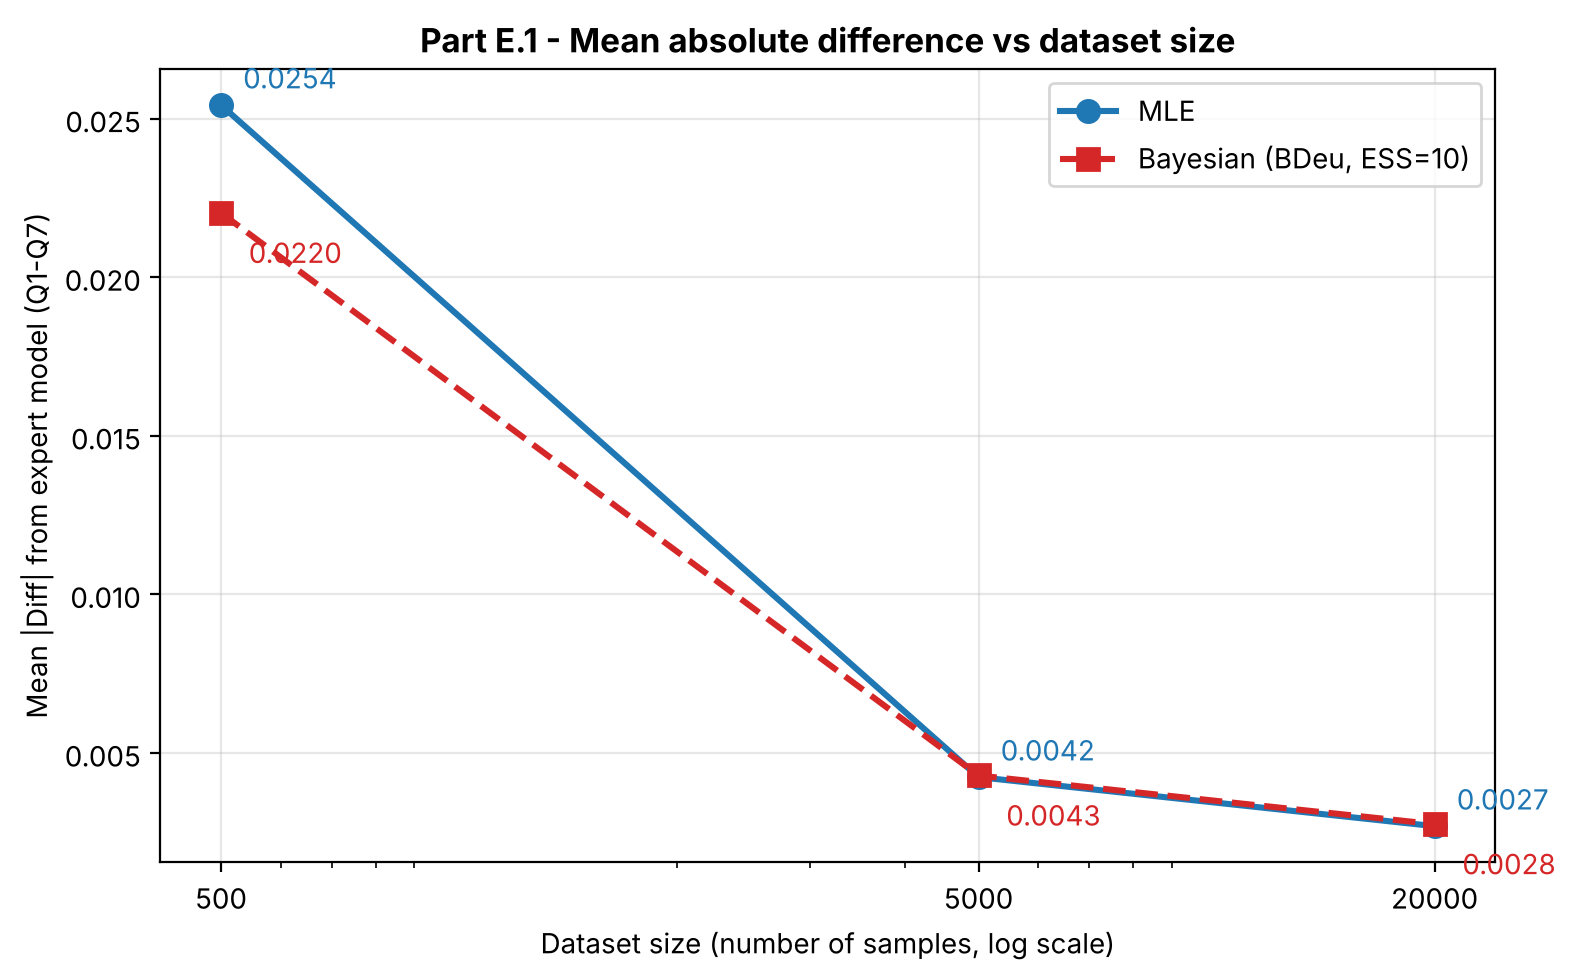


E.1  Plot saved -> outputs/E1_mean_abs_diff_vs_size.png
 Dataset size Mean |Diff| MLE Mean |Diff| Bayesian
          500          0.0254               0.0220
         5000          0.0042               0.0043
        20000          0.0027               0.0028


In [12]:
# E.1 plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(SIZES, mean_diff["MLE"], "o-", lw=2.2, ms=8, label="MLE", color="#1f77b4")
ax.plot(SIZES, mean_diff["Bayesian"], "s--", lw=2.2, ms=8,
        label="Bayesian (BDeu, ESS=10)", color="#d62728")
for x, y1, y2 in zip(SIZES, mean_diff["MLE"], mean_diff["Bayesian"]):
    ax.annotate(f"{y1:.4f}", (x, y1), textcoords="offset points", xytext=(8, 6), color="#1f77b4")
    ax.annotate(f"{y2:.4f}", (x, y2), textcoords="offset points", xytext=(10, -18), color="#d62728")
ax.set_xscale("log")
ax.set_xticks(SIZES)
ax.set_xticklabels([str(s) for s in SIZES])
ax.set_xlabel("Dataset size (number of samples, log scale)")
ax.set_ylabel("Mean |Diff| from expert model (Q1-Q7)")
ax.set_title("Part E.1 - Mean absolute difference vs dataset size", weight="bold")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, "E1_mean_abs_diff_vs_size.png"), dpi=150)
plt.show()
print("\nE.1  Plot saved -> outputs/E1_mean_abs_diff_vs_size.png")
md = pd.DataFrame({"Dataset size": SIZES,
                   "Mean |Diff| MLE": [f"{x:.4f}" for x in mean_diff["MLE"]],
                   "Mean |Diff| Bayesian": [f"{x:.4f}" for x in mean_diff["Bayesian"]]})
print(md.to_string(index=False))

### E.2 Largest error at n = 500

In [13]:
# E.2 largest error at n = 500, with evidence frequency
print("\nE.2  Largest error on the 500-sample dataset")
t500 = comp_tables[500]
df500 = datasets[500]
for est in ["MLE", "Bayesian"]:
    col = f"|Diff| {est}"
    q = t500.loc[t500[col].idxmax(), "Query"]
    print(f"  Largest {est} error: {q} ({q_text(q)})  |Diff| = {t500[col].max():.4f}")
print("  How often each query's evidence occurs in the 500-sample data:")
ev_rows = []
for q in QUERIES:
    _, _, ev = QUERIES[q]
    mask = np.ones(len(df500), bool)
    for k, v in ev.items():
        mask &= (df500[k] == v).values
    cnt = int(mask.sum())
    print(f"    {q}: evidence {ev if ev else '{none}'} -> {cnt} samples ({cnt/len(df500):.1%})"
          f"   |Diff| MLE = {t500.loc[t500.Query == q, '|Diff| MLE'].values[0]:.4f}"
          f"   |Diff| Bayes = {t500.loc[t500.Query == q, '|Diff| Bayesian'].values[0]:.4f}")
    ev_rows.append([q, ", ".join(f"{k}={v}" for k, v in ev.items()) or "none", cnt,
                    f"{cnt/len(df500):.1%}",
                    f"{t500.loc[t500.Query == q, '|Diff| MLE'].values[0]:.4f}",
                    f"{t500.loc[t500.Query == q, '|Diff| Bayesian'].values[0]:.4f}"])
evdf = pd.DataFrame(ev_rows, columns=["Query", "Evidence", "# samples", "% of data",
                                      "|Diff| MLE", "|Diff| Bayesian"])
evdf.index.name = "__noindex__"
save_table_image(evdf, "E2_evidence_frequency_n500.png",
                 "Part E.2 - Evidence frequency vs error (n = 500)", col_width=2.0)

print("\nDone. All outputs written to:", os.path.abspath(OUT))


E.2  Largest error on the 500-sample dataset
  Largest MLE error: Q4 (P(EnergyConsumption=High | Weather=Cold, Occupancy=High))  |Diff| = 0.0472
  Largest Bayesian error: Q4 (P(EnergyConsumption=High | Weather=Cold, Occupancy=High))  |Diff| = 0.0422
  How often each query's evidence occurs in the 500-sample data:
    Q1: evidence {none} -> 500 samples (100.0%)   |Diff| MLE = 0.0016   |Diff| Bayes = 0.0001
    Q2: evidence {'Weather': 'Hot'} -> 246 samples (49.2%)   |Diff| MLE = 0.0404   |Diff| Bayes = 0.0334
    Q3: evidence {'DayType': 'Weekend'} -> 154 samples (30.8%)   |Diff| MLE = 0.0176   |Diff| Bayes = 0.0221
    Q4: evidence {'Weather': 'Cold', 'Occupancy': 'High'} -> 65 samples (13.0%)   |Diff| MLE = 0.0472   |Diff| Bayes = 0.0422
    Q5: evidence {'EnergyConsumption': 'High'} -> 292 samples (58.4%)   |Diff| MLE = 0.0228   |Diff| Bayes = 0.0145
    Q6: evidence {'EnergyConsumption': 'High'} -> 292 samples (58.4%)   |Diff| MLE = 0.0312   |Diff| Bayes = 0.0271
    Q7: evidence {


Done. All outputs written to: /home/claude/Problem1_Submission/outputs
